# 🗳️ Last Digits vs. Benford's Law: Election Fraud in Nigeria (2003) and Sweden (2002)

The [Benford's Law notebook](../benfords-test/benfords-analysis.ipynb) showed that DC government purchase-card amounts follow Benford's first-digit distribution. This notebook asks the follow-up question: **what happens when you point the same tests at data where fraud is known to have happened?**

It compares two elections:

- **Nigeria, 2003 presidential election, Plateau State.** Polling-station returns from an election widely reported as rigged.
- **Sweden, 2002 parliamentary election.** Ward returns from an election nobody suspects of fraud. It is the control group.

The result is a lesson in choosing the right test. Benford's first-digit test flags *both* elections, so it cannot tell them apart. A different digit test, which checks whether the **last digit** of each vote count is uniformly distributed, separates the rigged election from the clean one. This replicates the main result of [Beber & Scacco (2012)](https://doi.org/10.1093/pan/mps003).

## ✨ Background

### Why fabricated vote counts leave fingerprints in the last digit

In a genuine count of a few hundred ballots, the last digit is essentially noise. A polling station is as likely to report 347 votes as 340 or 349, so each digit from 0 to 9 should appear about 10% of the time. Beber & Scacco show by simulation that this holds for a wide range of distributions, as long as the counts are not too small.

People who invent numbers do not produce that kind of noise. They favor some digits and avoid others. Officials who fill in tally sheets by hand also have a practical reason to favor round numbers: numbers ending in 0 are easier to add up when the fake sheets must reconcile.

### Why not Benford's first-digit test?

Benford's Law describes data that span several orders of magnitude, such as purchase-card amounts that run from a few dollars to tens of thousands. Polling stations are designed to be roughly the same size, so vote counts sit in a narrow band and their first digit mostly reflects how big a polling station is. Mark Nigrini, whose MAD thresholds the Benford notebook uses, has [said](https://nigrini.com/2020-presidential-election-wall-street-journal-publishes-an-article-on-fraud-and-benfords-law/) that the first-digit test is not a valid fraud tool for "almost equal-sized voting precincts". This notebook shows why.

### The fraud

Nigeria's 2003 elections were marred by widespread irregularities. Beber & Scacco chose Plateau State because, in Kew's (2004) account, its results "grew increasingly questionable as they moved through the LGA and state collation centers." They hand-entered the polling-station returns from the original handwritten result sheets. Note that the fraud label rests on election observers' and scholars' accounts, not on a court ruling.

### Data

Both files come unmodified from the authors' replication deposit, which is in the public domain (CC0 1.0):

> Beber, Bernd, and Alexandra Scacco. 2012. "Replication data for: What the Numbers Say: A Digit-Based Test for Election Fraud." Harvard Dataverse. [hdl:1902.1/17151](https://dataverse.harvard.edu/dataset.xhtml?persistentId=hdl:1902.1/17151)

| File | Unit | Rows |
|---|---|---|
| `Nigeria_2003_Presidential_Plateau_polling_stations.csv` | Polling station | 2,580 |
| `Sweden_2002_Riksdagsval.csv` | Ward (*valdistrikt*) | 6,266 |

## Import packages

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats

pio.templates['sans_serif'] = go.layout.Template(dict(layout=go.Layout(
    font_family='Helvetica, Inter, Arial, sans-serif')))
pio.templates.default = 'simple_white+sans_serif'

COUNTRY_COLORS = {'Nigeria 2003': '#D1495B', 'Sweden 2002': '#00798C'}
EXPECTED_COLOR = '#9E9E9E'

---

## 📥 Load and clean the data

### Nigeria

Each row is one polling station. The file has one column per party, plus registered voters (`regvoters`) and total votes (`totalvotes`).

In [2]:
nga_raw = pd.read_csv('Nigeria_2003_Presidential_Plateau_polling_stations.csv')
print(nga_raw.shape)
nga_raw.head(3)

(2580, 40)


,lga,lgacode,ward,wardcode,sheet,pstat,pstatcode,regvoters,AD,ANPP,...,PAC,PDP,PMP,PRP,PSD,PSP,UDP,UNPP,rejects,totalvotes
0,barkin ladi,1,barkin ladi,1,NaN,katako,1,750,3,357,...,NaN,215.0,1,NaN,NaN,NaN,NaN,7,26,615.0
1,barkin ladi,1,barkin ladi,1,NaN,st. mark's prim 1,2,505,4,131,...,NaN,213.0,1,NaN,NaN,1,1,3,6,367.0
2,barkin ladi,1,barkin ladi,1,NaN,gangare,3,502,2,165,...,1,196.0,1,1,1,NaN,NaN,2,3,380.0


A blank party cell means the party received no votes at that polling station, which is how the authors coded it. Some blank cells contain a space instead of being empty, so pandas reads those party columns as text. Converting them to numbers and filling the blanks with 0 follows the authors' rule.

Ten polling stations have no total. The authors attribute these to unreadable photocopies, so the tests below simply skip them.

In [3]:
id_cols = ['lga', 'lgacode', 'ward', 'wardcode', 'sheet', 'pstat', 'pstatcode', 'regvoters', 'totalvotes']
party_cols = [c for c in nga_raw.columns if c not in id_cols]

nga = nga_raw.copy()
nga[party_cols] = nga[party_cols].apply(pd.to_numeric, errors='coerce').fillna(0).astype(int)
nga = nga.rename(columns={'regvoters': 'registered', 'totalvotes': 'total'})

n_wards = nga[['lgacode', 'wardcode']].drop_duplicates().shape[0]
print(f"{len(nga):,} polling stations in {n_wards} wards and {nga['lgacode'].nunique()} local government areas")
print(f"Polling stations with no total: {nga['total'].isna().sum()}")

2,580 polling stations in 204 wards and 17 local government areas
Polling stations with no total: 10


The two largest parties were the ruling **PDP** (President Obasanjo, who won the election) and the opposition **ANPP** (Muhammadu Buhari).

In [4]:
nga[party_cols].sum().sort_values(ascending=False).head(5).to_frame('votes')

,votes
PDP,693609
ANPP,320696
AD,43880
rejects,32690
UNPP,7734


### Sweden

Each row is one ward. The file is Latin-1 encoded and uses Swedish column names. A few hundred rows are not wards: their ward code contains `R`, their name is *I vallokal ej räknande röster* (votes not counted at the polling station) and they have no registered voters. The authors drop them, and so does this notebook.

The two largest parties were the governing **Social Democrats** (`S`) and the opposition **Moderates** (`M`).

In [5]:
swe_raw = pd.read_csv('Sweden_2002_Riksdagsval.csv', encoding='latin-1')
print(swe_raw.shape)

swe = swe_raw[~swe_raw['Distriktskod'].str.contains('R')].rename(columns={
    'Län': 'county',
    'Kommun': 'municipality',
    'Distriktskod': 'ward_code',
    'Namn på valdistrikt': 'ward_name',
    'Antal röstberättigade': 'registered',
    'Total': 'total',
})
print(f"{len(swe):,} wards after dropping {len(swe_raw) - len(swe)} non-ward rows")
swe.head(3)

(6266, 15)
5,976 wards after dropping 290 non-ward rows


,county,municipality,ward_code,ward_name,Kommunvalkrets,registered,M,C,FP,KD,S,V,MP,Other,total
0,1,14,101,Upplands Väsby 1,2,1677,170,32,177,94,551,110,95,48,1277
1,1,14,102,Upplands Väsby 2,2,1312,181,22,187,78,417,77,76,34,1072
2,1,14,120,Upplands Väsby 20,2,1567,207,37,165,87,468,129,71,53,1217


### The four vote columns to test

Following Beber & Scacco, the tests use the same four columns for each election: votes for the largest party, votes for the second party, registered voters and total votes.

In [6]:
ELECTIONS = {
    'Nigeria 2003': {
        'Largest party': nga['PDP'],
        'Second party': nga['ANPP'],
        'Registered voters': nga['registered'],
        'Total votes': nga['total'].dropna(),
    },
    'Sweden 2002': {
        'Largest party': swe['S'],
        'Second party': swe['M'],
        'Registered voters': swe['registered'],
        'Total votes': swe['total'],
    },
}

---

## 📏 How big is a polling station?

Before running any digit test, check how much the counts vary. Benford's Law needs data that span several orders of magnitude.

In [7]:
size_summary = pd.DataFrame({
    country: columns['Total votes'].describe(percentiles=[0.05, 0.5, 0.95])
    for country, columns in ELECTIONS.items()
}).T[['count', 'min', '5%', '50%', '95%', 'max']]

size_summary['orders of magnitude (5%-95%)'] = np.log10(size_summary['95%'] / size_summary['5%'])
size_summary.round(1)

,count,min,5%,50%,95%,max,orders of magnitude (5%-95%)
Nigeria 2003,2570.0,0.0,200.0,426.5,682.5,1188.0,0.5
Sweden 2002,5976.0,69.0,345.8,908.0,1346.0,1890.0,0.6


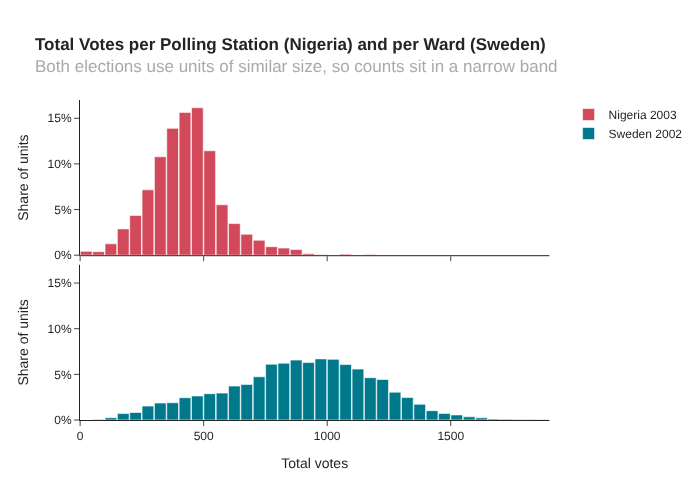

In [8]:
size_df = pd.concat([
    pd.DataFrame({'Total votes': columns['Total votes'], 'Election': country})
    for country, columns in ELECTIONS.items()
])

fig = px.histogram(
    size_df,
    x='Total votes',
    color='Election',
    facet_row='Election',
    histnorm='percent',
    nbins=60,
    color_discrete_map=COUNTRY_COLORS,
    height=500,
    title='<b>Total Votes per Polling Station (Nigeria) and per Ward (Sweden)</b><br>'
          '<span style="color: #aaa">Both elections use units of similar size, so counts sit in a narrow band</span>',
)
fig.for_each_annotation(lambda a: a.update(text=''))
fig.update_yaxes(title_text='Share of units', ticksuffix='%')
fig.update_layout(showlegend=True, legend_title=None, bargap=0.05)
fig.show()

The middle 90% of Nigerian polling stations report between 200 and about 680 votes; the middle 90% of Swedish wards report between about 350 and 1,350. Neither spans even one full order of magnitude. Compare that with the purchase-card amounts in the Benford notebook, which run from under \$10 to over \$10,000.

---

## 1️⃣ Step 1: Run the Benford tests from the Benford notebook

The functions below reproduce the first-digit and second-digit tests and Nigrini's MAD thresholds from the Benford notebook.

In [9]:
BENFORD_FIRST = pd.Series(np.log10(1 + 1 / np.arange(1, 10)), index=range(1, 10))
BENFORD_SECOND = pd.Series(
    [sum(np.log10(1 + 1 / (10 * d1 + d2)) for d1 in range(1, 10)) for d2 in range(10)],
    index=range(10),
)


def first_digit_proportions(values):
    digits = values[values >= 1].astype('int64').astype(str).str[0].astype(int)
    return digits.value_counts(normalize=True).reindex(range(1, 10), fill_value=0)


def second_digit_proportions(values):
    digits = values[values >= 10].astype('int64').astype(str).str[1].astype(int)
    return digits.value_counts(normalize=True).reindex(range(10), fill_value=0)


def mad(actual, expected):
    return (actual - expected).abs().mean()


def benford_first_digit_interpretation_MAD(mad):
    if mad < 0.006:
        return 'Close Conformity'
    elif mad < 0.012:
        return 'Acceptable Conformity'
    elif mad < 0.015:
        return 'Marginal Conformity'
    else:
        return 'Nonconformity'


def benford_second_digit_interpretation_MAD(mad):
    if mad < 0.008:
        return 'Close Conformity'
    elif mad < 0.010:
        return 'Acceptable Conformity'
    elif mad < 0.012:
        return 'Marginal Conformity'
    else:
        return 'Nonconformity'

In [10]:
benford_rows = []
for country, columns in ELECTIONS.items():
    for column, values in columns.items():
        first_mad = mad(first_digit_proportions(values), BENFORD_FIRST)
        second_mad = mad(second_digit_proportions(values), BENFORD_SECOND)
        benford_rows.append({
            'election': country,
            'column': column,
            'first-digit MAD': round(first_mad, 4),
            'first-digit verdict': benford_first_digit_interpretation_MAD(first_mad),
            'second-digit MAD': round(second_mad, 4),
            'second-digit verdict': benford_second_digit_interpretation_MAD(second_mad),
        })

benford_results = pd.DataFrame(benford_rows)
benford_results

,election,column,first-digit MAD,first-digit verdict,second-digit MAD,second-digit verdict
0,Nigeria 2003,Largest party,0.0473,Nonconformity,0.0094,Acceptable Conformity
1,Nigeria 2003,Second party,0.0221,Nonconformity,0.0062,Close Conformity
2,Nigeria 2003,Registered voters,0.1063,Nonconformity,0.0122,Nonconformity
3,Nigeria 2003,Total votes,0.0970,Nonconformity,0.0185,Nonconformity
4,Sweden 2002,Largest party,0.0687,Nonconformity,0.0061,Close Conformity
5,Sweden 2002,Second party,0.0221,Nonconformity,0.0040,Close Conformity
6,Sweden 2002,Registered voters,0.0917,Nonconformity,0.0293,Nonconformity
7,Sweden 2002,Total votes,0.0683,Nonconformity,0.0256,Nonconformity


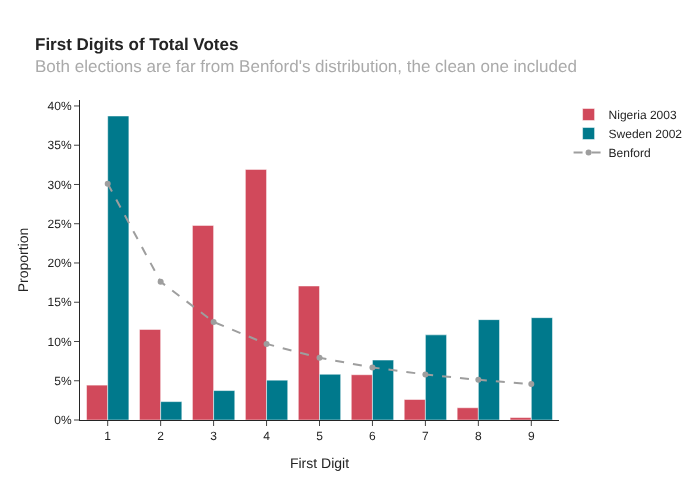

In [11]:
first_digit_df = pd.concat([
    first_digit_proportions(columns['Total votes']).rename('proportion').rename_axis('digit').reset_index().assign(Election=country)
    for country, columns in ELECTIONS.items()
])

fig = px.bar(
    first_digit_df,
    x='digit',
    y='proportion',
    color='Election',
    barmode='group',
    color_discrete_map=COUNTRY_COLORS,
    height=500,
    title="<b>First Digits of Total Votes</b><br>"
          "<span style=\"color: #aaa\">Both elections are far from Benford's distribution, the clean one included</span>",
    labels={'digit': 'First Digit'},
)
fig.add_trace(go.Scatter(
    x=BENFORD_FIRST.index, y=BENFORD_FIRST.values, name='Benford',
    mode='lines+markers', line=dict(color=EXPECTED_COLOR, dash='dash'),
))
fig.update_layout(yaxis_title_text='Proportion', yaxis_tickformat=',.0%', legend_title=None)
fig.update_xaxes(dtick=1)
fig.show()

Every column fails the first-digit test in **both** elections, and the clean Swedish election fails as badly as the rigged Nigerian one. The shapes simply mirror unit sizes. Most Nigerian polling stations report between 300 and 499 votes, so their totals peak at leading digits 3 and 4. Swedish totals pile up on a leading 1 (wards with 1,000 votes or more) and on 7 to 9 (wards with 700 to 999), with almost nothing at 2.

The second-digit test does no better: it flags registered voters and total votes in both elections and passes the party columns in both. A test that flags the control group cannot be used to flag fraud. Benford's Law is the wrong reference distribution for these data.

---

## 2️⃣ Step 2: Test the last digit instead

If the counts are genuine, each last digit from 0 to 9 should appear about 10% of the time. A chi-square goodness-of-fit test compares the observed last-digit counts with that uniform expectation (9 degrees of freedom). The function also reports a MAD against 10%, an effect size that, unlike the p-value, does not grow with the sample size.

In [12]:
def last_digit_counts(values, min_value=0):
    values = values.dropna().astype('int64')
    values = values[values >= min_value]
    return (values % 10).value_counts().reindex(range(10), fill_value=0)


def last_digit_test(values, min_value=0):
    counts = last_digit_counts(values, min_value)
    chi2, p_value = stats.chisquare(counts)
    proportions = counts / counts.sum()
    return {
        'n': int(counts.sum()),
        'share ending in 0': round(proportions[0], 3),
        'chi-square': round(chi2, 1),
        'p-value': p_value,
        'last-digit MAD': round((proportions - 0.1).abs().mean(), 4),
    }

In [13]:
last_digit_results = pd.DataFrame([
    {'election': country, 'column': column, **last_digit_test(values)}
    for country, columns in ELECTIONS.items()
    for column, values in columns.items()
])

last_digit_results.style.format({'p-value': '{:.2g}', 'share ending in 0': '{:.1%}'}).hide(axis='index')

election,column,n,share ending in 0,chi-square,p-value,last-digit MAD
Nigeria 2003,Largest party,2580,11.9%,21.300000,0.011,0.007100
Nigeria 2003,Second party,2580,13.2%,40.800000,5.5e-06,0.008900
Nigeria 2003,Registered voters,2580,16.1%,114.600000,1.7e-20,0.013100
Nigeria 2003,Total votes,2570,20.0%,298.300000,6.1e-59,0.021000
Sweden 2002,Largest party,5976,10.2%,5.400000,0.8,0.002700
Sweden 2002,Second party,5976,9.9%,7.700000,0.56,0.002900
Sweden 2002,Registered voters,5976,9.9%,7.800000,0.55,0.002700
Sweden 2002,Total votes,5976,9.8%,3.900000,0.92,0.002300


The last-digit test separates the two elections cleanly:

- **Nigeria:** all four columns reject uniform last digits. The p-values replicate the published ones: about 0.01 for the PDP (largest party) and below 0.0001 for the other three columns.
- **Sweden:** none of the four columns comes close to rejecting.

The MAD column tells the same story as an effect size: Nigerian columns deviate from 10% several times more than Swedish ones.

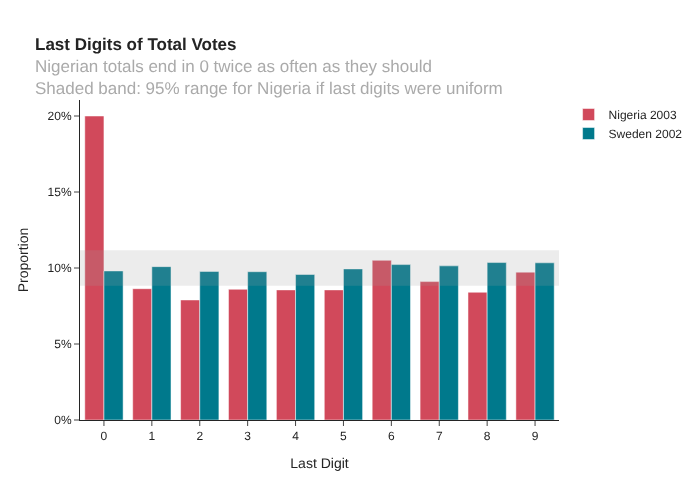

In [14]:
last_digit_df = pd.concat([
    (last_digit_counts(columns['Total votes']) / last_digit_counts(columns['Total votes']).sum())
    .rename('proportion').rename_axis('digit').reset_index().assign(Election=country)
    for country, columns in ELECTIONS.items()
])

n_nigeria = last_digit_counts(ELECTIONS['Nigeria 2003']['Total votes']).sum()
margin = 1.96 * np.sqrt(0.1 * 0.9 / n_nigeria)

fig = px.bar(
    last_digit_df,
    x='digit',
    y='proportion',
    color='Election',
    barmode='group',
    color_discrete_map=COUNTRY_COLORS,
    height=500,
    title='<b>Last Digits of Total Votes</b><br>'
          '<span style="color: #aaa">Nigerian totals end in 0 twice as often as they should<br>'
          'Shaded band: 95% range for Nigeria if last digits were uniform</span>',
    labels={'digit': 'Last Digit'},
)
fig.add_hrect(y0=0.1 - margin, y1=0.1 + margin, fillcolor=EXPECTED_COLOR, opacity=0.2, line_width=0)
fig.add_hline(y=0.1, line_dash='dash', line_color=EXPECTED_COLOR)
fig.update_layout(yaxis_title_text='Proportion', yaxis_tickformat=',.0%', legend_title=None)
fig.update_xaxes(dtick=1)
fig.show()

---

## 3️⃣ Step 3: Where is the signal? Zeros

The chart points at one digit: 0. If the excess zeros are the whole story, removing them should make the remaining digits look uniform. Following the authors, the test below pools all four columns, drops the values that end in 0 and tests whether digits 1 to 9 are equally common (8 degrees of freedom).

In [15]:
nonzero_rows = []
for country, columns in ELECTIONS.items():
    pooled_counts = sum(last_digit_counts(values) for values in columns.values())
    chi2, p_value = stats.chisquare(pooled_counts[1:])
    nonzero_rows.append({
        'election': country,
        'values': int(pooled_counts.sum()),
        'share ending in 0': pooled_counts[0] / pooled_counts.sum(),
        'chi-square (digits 1-9)': round(chi2, 1),
        'p-value (digits 1-9)': round(p_value, 3),
    })

pd.DataFrame(nonzero_rows).style.format({'share ending in 0': '{:.1%}'}).hide(axis='index')

election,values,share ending in 0,chi-square (digits 1-9),p-value (digits 1-9)
Nigeria 2003,10310,15.3%,13.200000,0.106000
Sweden 2002,23904,10.0%,2.400000,0.968000


Once the zeros are removed, Nigeria's remaining digits no longer reject uniformity at the 5% level (the paper reports p ≈ 0.11 for this test). The fingerprint of this fraud is an excess of round numbers, consistent with officials writing down tallies instead of counting ballots.

---

## 4️⃣ Step 4: Watch out for small counts

The last-digit test assumes counts are large enough for the last digit to be noise. For a count below 10, the last digit *is* the first digit, and small numbers are not uniform: a minor party is more likely to get 1 or 2 votes than 8 or 9. That bias can mimic or mask fraud.

The ANPP column has the most small counts. Re-running the test on counts of at least 10 and at least 100 checks whether the result survives.

In [16]:
anpp = nga['ANPP']
print(f"ANPP counts below 10: {(anpp < 10).mean():.1%} of polling stations")

pd.DataFrame([
    {'ANPP counts included': label, **last_digit_test(anpp, min_value)}
    for label, min_value in [('all', 0), ('10 or more', 10), ('100 or more', 100)]
]).style.format({'p-value': '{:.2g}', 'share ending in 0': '{:.1%}'}).hide(axis='index')

ANPP counts below 10: 13.4% of polling stations


ANPP counts included,n,share ending in 0,chi-square,p-value,last-digit MAD
all,2580,13.2%,40.800000,5.5e-06,0.008900
10 or more,2234,12.4%,23.400000,0.0054,0.007900
100 or more,980,11.0%,20.700000,0.014,0.011800


The deviation survives when small counts are dropped, so it is not an artifact of small numbers. The excess of zeros does shrink among counts of 100 or more (11% versus 13% overall), and with fewer observations the p-values weaken. Sample size and effect size both matter.

---

## 5️⃣ Step 5: Drill down to wards

A statewide test says *that* something is wrong, not *where*. Running the same test within each ward (pooling the four columns, as the authors do) shows how widespread the anomaly is. If the counts were genuine, p-values would be spread evenly between 0 and 1, and about 5% of wards would fall below 0.05 by chance. For Sweden, the comparable unit is the municipality.

In [17]:
VOTE_COLUMNS = {
    'Nigeria 2003': ['PDP', 'ANPP', 'registered', 'total'],
    'Sweden 2002': ['S', 'M', 'registered', 'total'],
}


def unit_level_tests(df, unit_cols, value_cols):
    long = df.melt(id_vars=unit_cols, value_vars=value_cols, value_name='votes').dropna(subset=['votes'])
    long['last_digit'] = long['votes'].astype('int64') % 10
    counts = (
        long.groupby(unit_cols)['last_digit'].value_counts()
        .unstack(fill_value=0)
        .reindex(columns=range(10), fill_value=0)
    )
    chi2, p_value = stats.chisquare(counts, axis=1)
    return counts.assign(n=counts.sum(axis=1), share_zero=counts[0] / counts.sum(axis=1), chi2=chi2, p_value=p_value)


nga_wards = unit_level_tests(nga, ['lga', 'ward'], VOTE_COLUMNS['Nigeria 2003'])
swe_munis = unit_level_tests(swe, ['county', 'municipality'], VOTE_COLUMNS['Sweden 2002'])

pd.DataFrame({
    'units tested': [len(nga_wards), len(swe_munis)],
    'median values per unit': [nga_wards['n'].median(), swe_munis['n'].median()],
    'share with p < 0.05': [(nga_wards['p_value'] < 0.05).mean(), (swe_munis['p_value'] < 0.05).mean()],
}, index=['Nigeria 2003 (wards)', 'Sweden 2002 (municipalities)']).style.format({'share with p < 0.05': '{:.1%}'})

,units tested,median values per unit,share with p < 0.05
Nigeria 2003 (wards),204,40.000000,13.7%
Sweden 2002 (municipalities),290,48.000000,5.5%


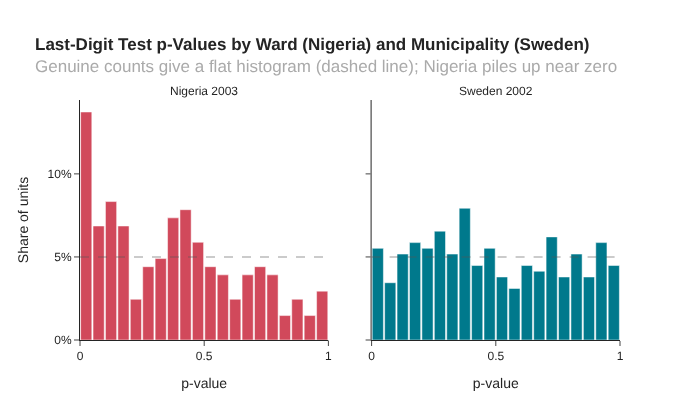

In [18]:
bin_edges = np.linspace(0, 1, 21)


def pvalue_bins(p_values, election):
    shares, _ = np.histogram(p_values, bins=bin_edges)
    return pd.DataFrame({'p-value bin': bin_edges[:-1] + 0.025, 'share': shares / shares.sum(), 'Election': election})


pvalue_df = pd.concat([
    pvalue_bins(nga_wards['p_value'], 'Nigeria 2003'),
    pvalue_bins(swe_munis['p_value'], 'Sweden 2002'),
])

fig = px.bar(
    pvalue_df,
    x='p-value bin',
    y='share',
    color='Election',
    facet_col='Election',
    facet_col_spacing=0.08,
    color_discrete_map=COUNTRY_COLORS,
    height=420,
    title='<b>Last-Digit Test p-Values by Ward (Nigeria) and Municipality (Sweden)</b><br>'
          '<span style="color: #aaa">Genuine counts give a flat histogram (dashed line); Nigeria piles up near zero</span>',
)
fig.add_hline(y=0.05, line_dash='dash', line_color='#555555', line_width=2)
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
fig.update_traces(width=0.045)
fig.update_xaxes(title_text='p-value')
fig.update_yaxes(title_text=None, tickformat=',.0%')
fig.update_yaxes(title_text='Share of units', col=1)
fig.update_layout(showlegend=False)
fig.show()

Sweden's municipalities produce a roughly flat histogram, as genuine counts should: 5.5% fall below 0.05. Nigerian wards pile up at small p-values: 13.7% fall below 0.05, almost three times the rate expected by chance, as the paper also reports. The anomaly is spread across many wards rather than confined to a few.

The wards with the strongest deviations are listed below. With around 200 tests, a handful of small p-values are expected by chance, so treat this list as leads for an audit, not as proof of fraud in any particular ward.

In [19]:
(nga_wards.sort_values('p_value')
    .head(10)[['n', 'share_zero', 'chi2', 'p_value']]
    .style.format({'share_zero': '{:.0%}', 'chi2': '{:.1f}', 'p_value': '{:.1g}'}))

,last_digit,n,share_zero,chi2,p_value
lga,ward,,,,
jos-north,naragata b,424,20%,63.1,3e-10
wase,bashar,48,40%,53.2,3e-08
jos-north,jos jarawa,147,24%,44.4,1e-06
wase,kadarko,64,31%,41.9,3e-06
bokkos,richa,28,32%,41.3,4e-06
wase,mavo,40,38%,40.0,8e-06
riyom,sharubutu,40,38%,38.5,1e-05
mangu,kombun,76,28%,31.9,0.0002
wase,wase-tofa,28,39%,31.3,0.0003


---

## 📌 Key Findings

1. **Benford's first-digit test cannot tell the rigged election from the clean one.** All four columns fail in both elections, with first-digit MADs of 0.022 to 0.106 in Nigeria and 0.022 to 0.092 in Sweden, against Nigrini's nonconformity cutoff of 0.015. Unit sizes span only about half an order of magnitude, far too little for Benford's Law. The second-digit test splits the same way in both elections.
2. **The last-digit test separates them.** Every Nigerian column rejects uniform last digits, with p-values from 0.011 (PDP votes) down to about 10⁻⁵⁹ (total votes), replicating Beber & Scacco (2012). No Swedish column comes close (p = 0.55 to 0.92).
3. **The fingerprint is an excess of round numbers.** 20.0% of Nigerian polling-station totals end in 0, against 9.8% of Swedish ward totals. With zeros removed, Nigeria's remaining digits are consistent with uniform (p = 0.11), which fits the picture of officials writing down round tallies instead of counting ballots.
4. **The result is robust and widespread.** It survives dropping small counts (ANPP counts of 10 or more: p = 0.005), and 13.7% of Nigerian wards reject at the 5% level, against 5.5% of Swedish municipalities.
5. **Match the reference distribution to how the data were generated.** Benford's Law fits amounts that span orders of magnitude, like purchase-card transactions. Counts from roughly equal-sized units call for a last-digit test. Either way, a digit test is a screening tool that tells auditors where to look, not proof of fraud.

## Case Study Potential

**Verdict: Strong.** The files are small, clean and in the public domain, and the clean control group ships in the same deposit. The case works as a direct sequel to the purchase-card notebook. Students reuse the Benford functions they already wrote, watch them fail on a control group, and then build a better test.

- **Strengths:** a documented fraud setting, a peer-reviewed result that replicates exactly, a built-in control and a memorable mechanism (officials writing round numbers).
- **Weaknesses:** the fraud label comes from observers and scholars, not a court, and digit tests can only raise suspicion; they never identify who did what.

**Suggested framing:** *An election-monitoring NGO has the scanned result sheets from a disputed election and a small audit budget. Which test should it trust, and which wards should it audit first?*

**Discussion questions:**

1. Why does the clean Swedish election fail the first-digit Benford test? What property of the data would have to change for Benford to apply?
2. The Nigerian fraud signal disappears once zeros are removed. What does that suggest about how the numbers were produced?
3. Chi-square p-values shrink as the sample grows. When would you rather report the last-digit MAD?
4. Which kinds of honest data would also fail a last-digit test (for example, prices like \$9.99 or counts below 10)?
5. A ward appears in the top-10 list. What other evidence would you want before calling it fraudulent?

## References

- Beber, B., & Scacco, A. (2012). What the Numbers Say: A Digit-Based Test for Election Fraud. *Political Analysis*, 20(2), 211–234. [doi:10.1093/pan/mps003](https://doi.org/10.1093/pan/mps003)
- Beber, B., & Scacco, A. (2012). Replication data for: What the Numbers Say. Harvard Dataverse, CC0 1.0. [hdl:1902.1/17151](https://dataverse.harvard.edu/dataset.xhtml?persistentId=hdl:1902.1/17151)
- Deckert, J., Myagkov, M., & Ordeshook, P. C. (2011). Benford's Law and the Detection of Election Fraud. *Political Analysis*, 19(3), 245–268.
- Medzihorsky, J. (2015). Election Fraud: A Latent Class Framework for Digit-Based Tests. *Political Analysis*.
- Nigrini, M. J. (2012). *Benford's Law: Applications for Forensic Accounting, Auditing, and Fraud Detection*. Wiley.